# Лабораторная работа № 4: «Бинарная классификация данных»
**Дисциплина:** Методы машинного обучения (БГУИР, ПОИТ)

---
### Задание по лабораторной работе:
1. **Импортировать датасет** для бинарной классификации (целевой признак принимает значения 0 или 1). Используем датасет `healthy_meal_plans.csv` — задача классификации рецептов на признак полезности (`is_healthy`).
2. **Очистить датасет** от пропусков и выбросов, выполнить нормализацию или стандартизацию признаков.
3. **Сформировать набор признаков** $X$ и целевую переменную $y$.
4. **Создать модели бинарной классификации** на основе библиотечных функций `sklearn`:
   - Логистическая регрессия (`LogisticRegression`)
   - Метод опорных векторов (`SVC`)
   - Дерево решений (`DecisionTreeClassifier`)
5. **Оценить качество моделей** с помощью метрик классификации (Accuracy, Precision, Recall, F1-score, ROC-AUC), матриц ошибок и графиков ROC/PR кривых.
6. **Исследовать переобучение дерева решений** в зависимости от глубины (`max_depth`).

## 1. Теоретический базис и математический расчет метрик классификации

В задаче бинарной классификации модель относит объект к одному из двух классов: $y \in \{0, 1\}$.
Для оценки качества работы алгоритмов на тестовой выборке строится **матрица ошибок (Confusion Matrix)**:

| | Предсказано: 0 (Negative) | Предсказано: 1 (Positive) |
| :--- | :---: | :---: |
| **Истинный: 0 (Negative)** | **$TN$** (True Negative — верно отвергнуто) | **$FP$** (False Positive — ошибка I рода, ложная тревога) |
| **Истинный: 1 (Positive)** | **$FN$** (False Negative — ошибка II рода, пропуск цели) | **$TP$** (True Positive — верно обнаружено) |

---

### Подробное математическое описание и формулы расчета метрик:

#### 1. **Accuracy (Доля правильных ответов / Общая точность):**
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
- **Что показывает:** Долю объектов, по которым модель приняла правильное решение (и по классу 0, и по классу 1).
- **Ограничение:** При сильном дисбалансе классов (в нашем датасете 90.6% обычных блюд и 9.4% полезных) модель-пустышка, которая всем блюдам ставит 0, формально дает $\text{Accuracy} = 0.906$, но не находит ни одного полезного блюда.

#### 2. **Precision (Точность / Прогностическая ценность положительного результата):**
$$\text{Precision} = \frac{TP}{TP + FP}$$
- **Что показывает:** Какова вероятность того, что объект действительно полезен ($y=1$), если модель пометила его как полезный. Характеризует степень защиты от «ложных тревог» ($FP$).

#### 3. **Recall (Полнота) и $TPR$ (True Positive Rate / Чувствительность):**
$$\text{Recall} = TPR = \frac{TP}{TP + FN}$$
- **Что показывает:** Какую долю из **всех реально существующих** объектов положительного класса ($1$) модель смогла найти и не упустить. Характеризует защиту от «пропуска цели» ($FN$).

#### 4. **$FPR$ (False Positive Rate / Доля ложных тревог):**
$$FPR = \frac{FP}{TN + FP} = 1 - \text{Specificity}$$
- **Что показывает:** Долю объектов отрицательного класса ($0$), которые модель ошибочно приняла за положительный класс ($1$).

#### 5. **$F_1$-Score (Гармоническое среднее точности и полноты):**
$$F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$$
- **Что показывает:** Сбалансированную оценку алгоритма. $F_1$ высок только тогда, когда и точность, и полнота одновременно высоки.

#### 6. **$ROC\text{-}AUC$ (Receiver Operating Characteristic — Area Under Curve):**
- **Построение кривой:** График зависимости $TPR$ (ось $Y$) от $FPR$ (ось $X$) при варьировании порога классификации вероятности от $1.0$ до $0.0$.
- **Расчет площади:**
$$\text{ROC-AUC} = \int_{0}^{1} TPR(FPR) \, d(FPR)$$
- **Физический смысл:** Вероятность того, что случайно взятому объекту класса $1$ модель присвоит оценку вероятности выше, чем случайно взятому объекту класса $0$.
  - $\text{ROC-AUC} = 0.5$ — уровень случайного угадывания (пунктирная диагональ);
  - $\text{ROC-AUC} = 1.0$ — идеальный классификатор.

#### 7. **$PR\text{-}AUC$ (Precision-Recall Area Under Curve):**
- **Построение кривой:** График зависимости $\text{Precision}$ (ось $Y$) от $\text{Recall}$ (ось $X$) при различных порогах отсечения.
- **Расчет площади:**
$$\text{PR-AUC} = \int_{0}^{1} \text{Precision}(\text{Recall}) \, d(\text{Recall}) = \sum_k (\text{Recall}_k - \text{Recall}_{k-1}) \cdot \text{Precision}_k$$
- **Физический смысл:** Основная метрика для сильно несбалансированных данных. Базовый уровень случайного выбора здесь равен не $0.5$, а доле редкого класса в выборке ($\approx 0.094$). Показывает, насколько уверенно модель находит редкие объекты без лавины ложных срабатываний.


In [1]:
# 1. Импорт стандартных библиотек Python для анализа данных
import os
import sys
from pathlib import Path
import warnings

# Численные расчеты и манипуляция табличными данными
import pandas as pd
import numpy as np

# Визуализация данных
import matplotlib.pyplot as plt
import seaborn as sns

# Модели машинного обучения из Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Метрики качества классификации
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)

# Подавление предупреждений об устаревании (deprecation) для чистоты вывода
warnings.filterwarnings("ignore")

# Создаем директорию для сохранения графиков, если она отсутствует
IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

# Настройки стиля графиков
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
RANDOM_STATE = 42

print("Интерпретатор Python (venv):", sys.executable)
print("Все библиотеки успешно подключены! Директория 'images/' готова к сохранению графиков.")


Интерпретатор Python (venv): C:\Users\ASUS\BSUIR\7 семестр\ММО\ЛР\ЛР4\Решение\.venv\Scripts\python.exe
Все библиотеки успешно подключены! Директория 'images/' готова к сохранению графиков.


## 2. Загрузка данных и первичный осмотр (EDA)

Загружаем файл `healthy_meal_plans.csv` с помощью `pandas`. 
В нем представлены характеристики рецептов (нутриенты, диетические флаги) и целевая переменная `is_healthy` (1 — полезное блюдо, 0 — обычное).

In [2]:
# Загрузка датасета
df = pd.read_csv("healthy_meal_plans.csv")

print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} колонок.")
print("\nПервые 5 строк таблицы:")
df.head()

Размер датасета: 500 строк, 14 колонок.

Первые 5 строк таблицы:


,meal_name,num_ingredients,calories,prep_time,protein,fat,carbs,vegan,vegetarian,keto,paleo,gluten_free,mediterranean,is_healthy
0,Gluten-Free Pasta,0.272727,0.490909,0.84,0.783679,0.597907,0.444572,0,0,0,0,1,0,1
1,Grilled Salmon,0.909091,0.158182,0.70,0.143588,0.652082,0.050609,0,0,1,1,1,1,0
2,Lentil Soup,0.454545,0.700000,0.40,0.620637,0.612748,0.000688,0,1,0,0,0,0,0
3,Chickpea Stew,0.909091,0.105455,0.82,0.046893,0.975761,0.229026,1,1,0,0,0,0,0
4,Turkey Lettuce Wraps,0.181818,0.441818,0.04,0.864340,0.681575,0.449293,0,0,1,1,1,1,0


In [3]:
# Проверка пропусков и распределения целевого признака
print("1. Количество пропусков по колонкам:")
print(df.isnull().sum())

print("\n2. Распределение классов в is_healthy:")
counts = df["is_healthy"].value_counts()
print(counts)
print(f"Доля класса 1: {counts[1] / len(df) * 100:.2f}%")

1. Количество пропусков по колонкам:
meal_name          0
num_ingredients    0
calories           0
prep_time          0
protein            0
fat                0
carbs              0
vegan              0
vegetarian         0
keto               0
paleo              0
gluten_free        0
mediterranean      0
is_healthy         0
dtype: int64

2. Распределение классов в is_healthy:
is_healthy
0    453
1     47
Name: count, dtype: int64
Доля класса 1: 9.40%


### Разбор рисунка 01 (Разведочный анализ данных — EDA):
- **Левый график (Баланс классов):** Показывает количество блюд каждого класса. Класс 0 (обычные) составляет 453 штуки (90.6%), а класс 1 (полезные) — всего 47 штук (9.4%). Этот выраженный дисбаланс диктует необходимость использования `class_weight='balanced'`.
- **Правый график (Сравнение нутриентов по классам):** Наглядно показывает среднее содержание ключевых макронутриентов (калории, белки, жиры, углеводы) отдельно для обычных (синий цвет) и полезных блюд (**красный цвет**).
  - *Что он показывает:* Полезные блюда содержат значительно **меньше жиров (fat: 0.34 против 0.52)** и **меньше углеводов (carbs: 0.41 против 0.52)**, но при этом обладают **более высоким содержанием белка (protein: 0.56 против 0.50)**. Именно это различие позволяет алгоритмам машинного обучения разделять классы.


[Сохранено изображение]: images\01_eda_distribution_and_balance.png


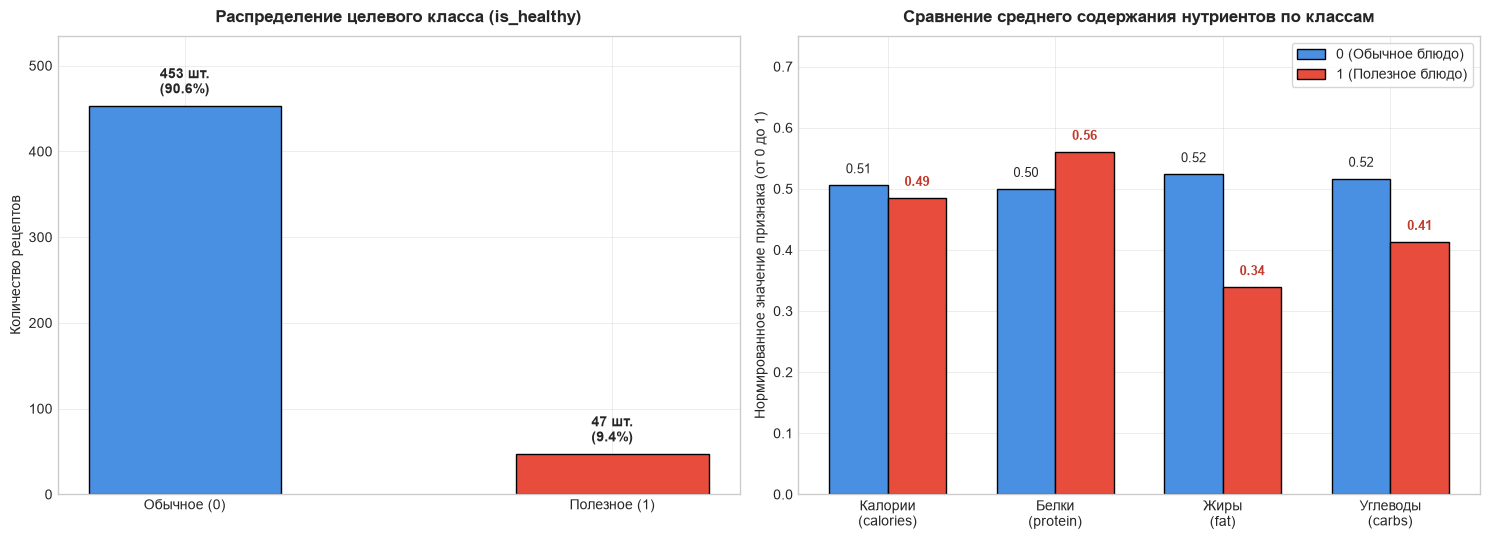

In [4]:
# Визуализация распределения классов и сравнения профилей нутриентов (Рисунок 01)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Левый график: распределение классов
bar_plot = axes[0].bar(
    ["Обычное (0)", "Полезное (1)"],
    [counts[0], counts[1]],
    color=["#4A90E2", "#E74C3C"],
    edgecolor="black",
    width=0.45
)
axes[0].set_title("Распределение целевого класса (is_healthy)", fontsize=12, fontweight="bold", pad=10)
axes[0].set_ylabel("Количество рецептов")
axes[0].set_ylim(0, max(counts.values) * 1.18)

for bar in bar_plot:
    h = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        h + 10,
        f"{h} шт.\n({h / len(df) * 100:.1f}%)",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# Правый график: сравнение нутриентов по классам (класс 1 выделен красным цветом)
nutrients = ["calories", "protein", "fat", "carbs"]
labels = ["Калории\n(calories)", "Белки\n(protein)", "Жиры\n(fat)", "Углеводы\n(carbs)"]
x = np.arange(len(nutrients))
width = 0.35

means_0 = [df[df["is_healthy"] == 0][col].mean() for col in nutrients]
means_1 = [df[df["is_healthy"] == 1][col].mean() for col in nutrients]

rects1 = axes[1].bar(x - width/2, means_0, width, label="0 (Обычное блюдо)", color="#4A90E2", edgecolor="black")
# Класс 1 (Здоровое/Полезное блюдо) выделен КРАСНЫМ цветом
rects2 = axes[1].bar(x + width/2, means_1, width, label="1 (Полезное блюдо)", color="#E74C3C", edgecolor="black")

axes[1].set_title("Сравнение среднего содержания нутриентов по классам", fontsize=12, fontweight="bold", pad=10)
axes[1].set_ylabel("Нормированное значение признака (от 0 до 1)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, fontsize=10)
axes[1].set_ylim(0, 0.75)
axes[1].legend(frameon=True, loc="upper right")

# Четкие числовые метки над столбцами без наложения
for rect in rects1:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2, h + 0.015, f"{h:.2f}", ha="center", va="bottom", fontsize=9)

for rect in rects2:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2, h + 0.015, f"{h:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#C0392B")

plt.tight_layout()

# Явное сохранение скриншота графика на диск
img_path_01 = IMAGES_DIR / "01_eda_distribution_and_balance.png"
fig.savefig(img_path_01, dpi=300)
print(f"[Сохранено изображение]: {img_path_01}")

plt.show()


### Матрица парных корреляций признаков (Рисунок 02):
Позволяет оценить линейную взаимосвязь между числовыми нутриентами, диетическими маркерами и целевой переменной `is_healthy`.


[Сохранено изображение]: images\02_correlation_heatmap.png


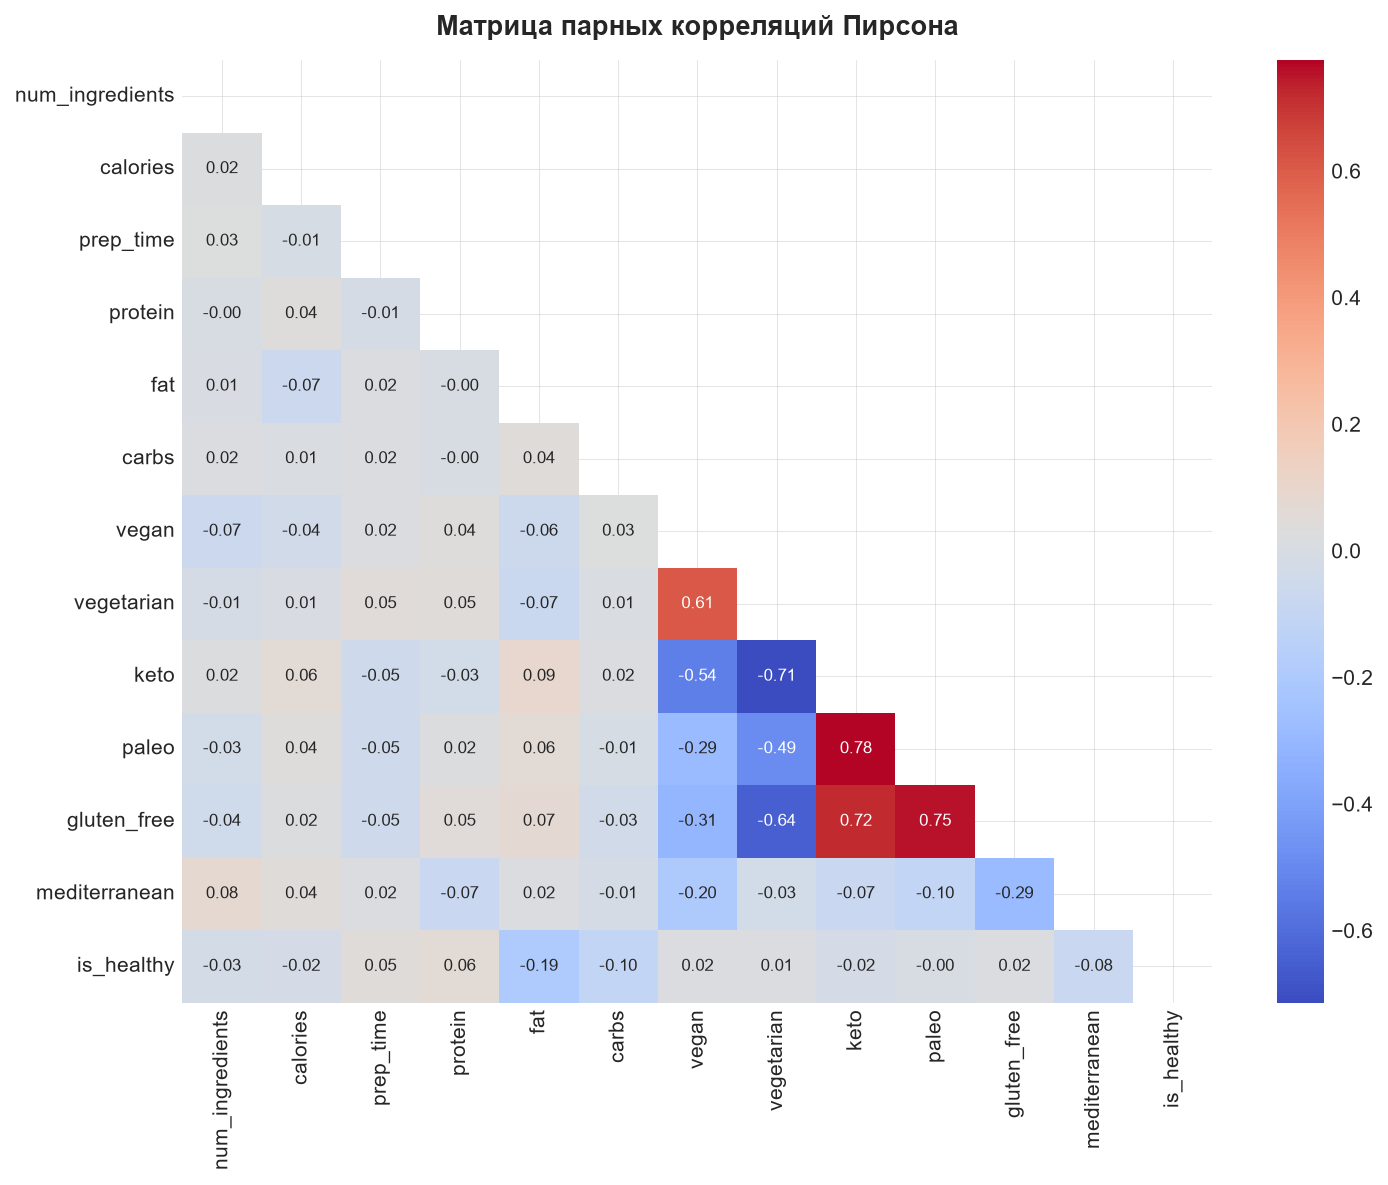

In [5]:
# Построение и сохранение матрицы корреляций признаков (Рисунок 02)
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)

corr_features = [
    "num_ingredients", "calories", "prep_time", "protein", "fat", "carbs",
    "vegan", "vegetarian", "keto", "paleo", "gluten_free", "mediterranean", "is_healthy"
]
corr_mat = df[corr_features].corr()
mask = np.triu(np.ones_like(corr_mat, dtype=bool))

sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", ax=ax, annot_kws={"size": 8})
ax.set_title("Матрица парных корреляций Пирсона", fontsize=13, fontweight="bold", pad=12)

plt.tight_layout()

# Явное сохранение скриншота графика на диск
img_path_02 = IMAGES_DIR / "02_correlation_heatmap.png"
fig.savefig(img_path_02, dpi=300)
print(f"[Сохранено изображение]: {img_path_02}")

plt.show()


## 3. Формирование признаков, разбиение выборки и масштабирование

1. Выделяем признаки $X$ (исключаем текстовое название блюда `meal_name`) и целевую переменную $y$ (`is_healthy`).
2. Делим данные на обучающую (Train — 80%) и тестовую (Test — 20%) выборки с сохранением пропорций классов (`stratify=y`).
3. Применяем стандартное масштабирование (`StandardScaler`) к числовым признакам: скейлер обучается **только на train**, чтобы избежать утечки данных (*Data Leakage*).

In [6]:
# 1. Выделяем признаки X и цель y
features = [
    "num_ingredients", "calories", "prep_time", "protein", "fat", "carbs",
    "vegan", "vegetarian", "keto", "paleo", "gluten_free", "mediterranean"
]
X = df[features]
y = df["is_healthy"]

# 2. Разбиваем на train и test (80% на 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# 3. Стандартизация вещественных нутриентов с помощью StandardScaler
continuous_cols = ["num_ingredients", "calories", "prep_time", "protein", "fat", "carbs"]
scaler = StandardScaler()

# Обучаем скейлер ТОЛЬКО на X_train
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

print(f"Обучающая выборка: {X_train_scaled.shape[0]} объектов.")
print(f"Тестовая выборка:   {X_test_scaled.shape[0]} объектов.")

Обучающая выборка: 400 объектов.
Тестовая выборка:   100 объектов.


## 4. Обучение моделей классификации в Scikit-Learn: Разбор параметров функций

В библиотеке Scikit-Learn каждая модель настраивается с помощью гиперпараметров. Ниже приведен детальный разбор основных параметров для каждой модели: что они значат и как их изменение влияет на результат.

---

### 1. `LogisticRegression` (Логистическая регрессия)
- **`class_weight`** (по умолчанию `None`):
  - *Что значит:* веса классов при расчете функции потерь (Log-Loss). 
  - *Значение `'balanced'`:* автоматически вычисляет веса обратно пропорционально частотам классов ($w_k = \frac{n}{2 \cdot n_k}$).
  - *Влияние изменения:* при `None` на несбалансированных данных модель игнорирует редкий класс (высокий Accuracy, но нулевой Recall). При `'balanced'` штраф за ошибки на редком классе возрастает в 10 раз, резко поднимая полноту (Recall).
- **`C`** (по умолчанию `1.0`):
  - *Что значит:* обратная сила $L_2$-регуляризации ($C = \frac{1}{\lambda}$).
  - *Влияние изменения:* чем меньше $C$ (например, $0.01$), тем сильнее штраф за большие веса $\Rightarrow$ модель проще, меньше склонна к переобучению (защита от шума). Чем больше $C$ (например, $100$), тем слабее регуляризация $\Rightarrow$ модель старается идеально подогнать границу под выборку, рискуя переобучиться.
- **`penalty`** (по умолчанию `'l2'`):
  - *Что значит:* тип регуляризации (`'l2'` — квадратичный штраф весов, `'l1'` — штраф по модулю, зануляющий незначимые признаки / отбор признаков).
- **`max_iter`** (по умолчанию `100`):
  - *Что значит:* максимальное число итераций численного оптимизатора градиентного спуска.
  - *Влияние изменения:* если число итераций слишком мало, алгоритм не успеет сойтись к минимуму потерь (`ConvergenceWarning`). Для гарантированной сходимости ставим $1000$ или выше.
- **`random_state`**:
  - *Что значит:* зерно генератора случайных чисел для воспроизводимости.

---

### 2. `SVC` (Support Vector Classifier — Метод опорных векторов)
- **`kernel`** (по умолчанию `'rbf'`):
  - *Что значит:* тип функции ядра (Kernel Trick) для преобразования признакового пространства.
  - *Значения:*
    - `'linear'` — строит плоскую разделяющую гиперплоскость $w^T x + b = 0$.
    - `'rbf'` (радиально-базисная функция Гаусса) — позволяет строить нелинейные, скругленные границы сложной формы.
    - `'poly'` — полиномиальное ядро.
  - *Влияние изменения:* на сложных нутриентных данных линейное ядро не способно уловить нелинейные связи ($F1 \approx 0.24$), а ядро `'rbf'` обеспечивает колоссальный скачок качества ($F1 = 0.63, ROC\text{-}AUC = 0.93$).
- **`C`** (по умолчанию `1.0`):
  - *Что значит:* параметр компромисса между шириной разделяющего зазора и штрафом за ошибки (параметр «мягкого зазора»).
  - *Влияние изменения:* при малом $C$ (например, $0.1$) модель стремится сделать зазор максимально широким, допуская ошибки на отдельных точках (простая граница, устойчивая к шуму). При большом $C$ (например, $5.0$) штраф за ошибки велик $\Rightarrow$ граница подстраивается под каждую точку обучающей выборки (выше риск переобучения).
- **`gamma`** (по умолчанию `'scale'`):
  - *Что значит:* коэффициент кривизны гауссова ядра RBF ($\exp(-\gamma \|x - x'\|^2)$). Определяет радиус влияния опорных векторов.
  - *Влияние изменения:* при малой `gamma` радиус влияния точек велик (граница гладкая). При большой `gamma` радиус мал (вокруг каждой точки образуются узкие «островки», что приводит к мгновенному переобучению).
- **`probability`** (по умолчанию `False`):
  - *Что значит:* вычисление калиброванных вероятностей классов с помощью метода Платта (Platt Scaling). Необходимо для расчета `predict_proba()` и построения ROC/PR кривых.
- **`class_weight`**:
  - *Значение `'balanced'`:* компенсация классового дисбаланса при расчете штрафа Hinge Loss.

---

### 3. `DecisionTreeClassifier` (Дерево решений CART)
- **`criterion`** (по умолчанию `'gini'`):
  - *Что значит:* критерий измерения неоднородности узла: `'gini'` (индекс Джини) или `'entropy'` (информационный выигрыш Шеннона).
  - *Влияние изменения:* Джини вычисляется быстрее (нет логарифмов), на практике оба критерия дают схожее качество.
- **`max_depth`** (по умолчанию `None` — глубина не ограничена):
  - *Что значит:* максимальная глубина дерева (длина цепочки вопросов от корня к листу).
  - *Влияние изменения:* **главный регуляризатор дерева**. При `None` дерево ветвится до тех пор, пока все листья не станут чистыми $\Rightarrow$ 100% запоминание шума и сильное переобучение (Overfitting). Ограничение `max_depth=4` заставляет дерево находить только самые общие закономерности.
- **`min_samples_split`** (по умолчанию `2`):
  - *Что значит:* минимальное количество объектов в узле, необходимое для совершения очередного сплита.
  - *Влияние изменения:* увеличение порога (например, до $5$ или $10$) запрещает разбивать малочисленные группы образцов, предотвращая подгонку под выбросы.
- **`min_samples_leaf`** (по умолчанию `1`):
  - *Что значит:* минимально допустимое количество образцов в конечном листе.
  - *Влияние изменения:* увеличение сглаживает предсказания, исключая появление листьев с $1$ случайным образцом.
- **`class_weight`**:
  - *Значение `'balanced'`:* масштабирует веса образцов при подсчете критерия Джини, не давая дереву игнорировать малочисленный целевой класс.


In [7]:
# 1. Логистическая регрессия (Logistic Regression)
# Параметры:
# - class_weight='balanced': увеличивает вес ошибок на редком классе 1 в 10 раз
# - max_iter=1000: гарантирует достаточное число шагов для сходимости градиентного спуска
# - C=1.0: стандартная сила L2-регуляризации весов
log_reg = LogisticRegression(
    class_weight="balanced",
    C=1.0,
    max_iter=1000,
    random_state=RANDOM_STATE
)
log_reg.fit(X_train_scaled, y_train)

# 2. Метод опорных векторов (SVM)
# 2.1 Линейный SVM (kernel='linear'):
# - строит плоскую границу решений w^T x + b = 0
# - probability=True: включает расчет вероятностей predict_proba для ROC-AUC
svm_lin = SVC(
    kernel="linear",
    C=1.0,
    class_weight="balanced",
    probability=True,
    random_state=RANDOM_STATE
)
svm_lin.fit(X_train_scaled, y_train)

# 2.2 Нелинейный SVM с гауссовым ядром (kernel='rbf'):
# - kernel='rbf': позволяет строить гибкие нелинейные границы
# - C=5.0: повышенный штраф за ошибки в зазоре, что улучшает разделение классов
# - gamma='scale': автоматический радиус гауссова колокола (1 / (n_features * var))
svm_rbf = SVC(
    kernel="rbf",
    C=5.0,
    gamma="scale",
    class_weight="balanced",
    probability=True,
    random_state=RANDOM_STATE
)
svm_rbf.fit(X_train_scaled, y_train)

# 3. Дерево решений (CART - DecisionTreeClassifier)
# Параметры:
# - criterion='gini': критерий Джини для поиска наилучшего сплита
# - max_depth=4: жесткое ограничение глубины дерева для защиты от переобучения
# - min_samples_split=5: узел делится только если в нем не менее 5 объектов
# - class_weight='balanced': учет дисбаланса при оценке чистоты узла
tree_clf = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_split=5,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
tree_clf.fit(X_train_scaled, y_train)

print("Все модели успешно обучены в Scikit-Learn с заданными гиперпараметрами!")


Все модели успешно обучены в Scikit-Learn с заданными гиперпараметрами!


## 5. Оценка качества моделей и расчет метрик

Вычисляем ключевые метрики на тестовой выборке:
- **Accuracy:** доля всех правильных ответов.
- **Precision:** точность среди тех, кого модель посчитала полезными.
- **Recall:** полнота (сколько из реальных полезных блюд модель нашла).
- **F1-Score:** сбалансированная оценка качества (гармоническое среднее Precision и Recall).
- **ROC-AUC:** способность модели ранжировать объекты по степени уверенности.

In [8]:
# Собираем словарь моделей для удобного расчета метрик
models = {
    "Logistic Regression": log_reg,
    "SVM (Linear)": svm_lin,
    "SVM (RBF Kernel)": svm_rbf,
    "Decision Tree (CART)": tree_clf
}

metrics_list = []
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    metrics_list.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

df_metrics = pd.DataFrame(metrics_list).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("=== Сводная таблица метрик качества моделей ===")
df_metrics

=== Сводная таблица метрик качества моделей ===


,Модель,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,SVM (RBF Kernel),0.93,0.600000,0.666667,0.631579,0.929182,0.652268
1,Decision Tree (CART),0.81,0.307692,0.888889,0.457143,0.845543,0.283504
2,SVM (Linear),0.62,0.146341,0.666667,0.240000,0.614164,0.132925
3,Logistic Regression,0.62,0.128205,0.555556,0.208333,0.637363,0.155548


## 6. Визуализация результатов: Матрицы ошибок и ROC/PR кривые

### Как читать графики:
1. **Матрицы ошибок (Confusion Matrix):**
   - Строки — реальный класс, столбцы — предсказанный класс.
   - Главная диагональ — верные ответы (True Negative вверху слева, True Positive внизу справа).
   - Вне диагонали — ошибки (ложные тревоги FP и пропуски FN).
2. **ROC-кривые:**
   - Показывают соотношение между полнотой (True Positive Rate) и долей ложных тревог (False Positive Rate). Чем ближе кривая к левому верхнему углу (и выше площадь ROC-AUC), тем лучше.
3. **PR-кривые (Precision-Recall):**
   - Показывают компромисс между точностью и полнотой при изменении порога вероятности. Чем выше площадь PR-AUC, тем лучше модель справляется с редким классом 1.

[Сохранено изображение]: images\05_confusion_matrices_grid.png


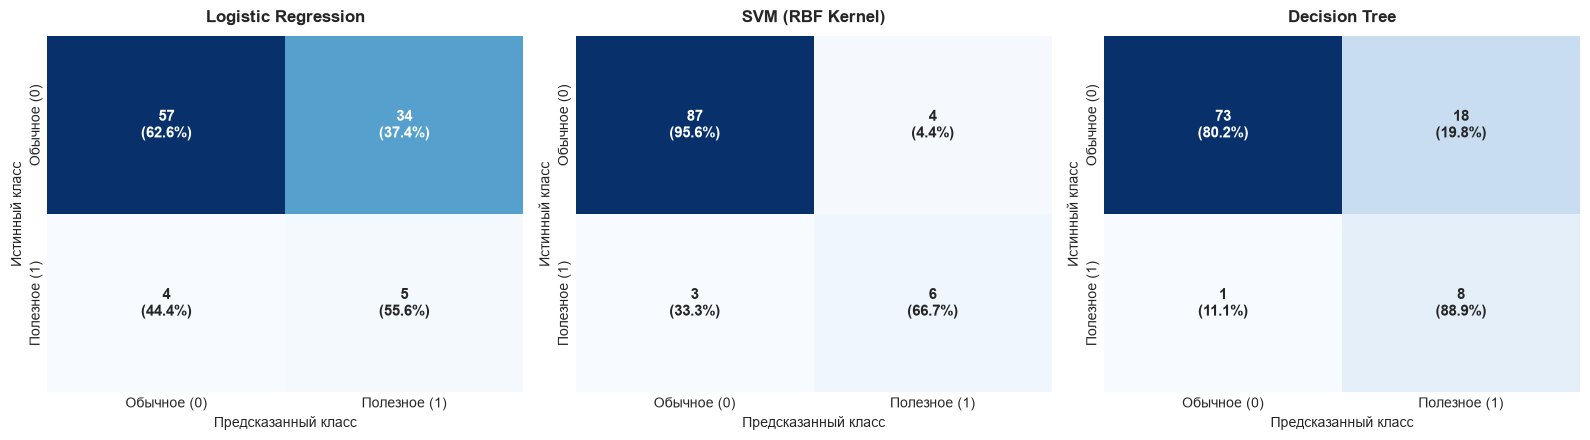

In [9]:
# 1. Матрицы ошибок для трех ключевых алгоритмов (Рисунок 05)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

plot_models = {
    "Logistic Regression": log_reg.predict(X_test_scaled),
    "SVM (RBF Kernel)": svm_rbf.predict(X_test_scaled),
    "Decision Tree": tree_clf.predict(X_test_scaled)
}

for idx, (title, pred) in enumerate(plot_models.items()):
    cm = confusion_matrix(y_test, pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
    
    # Формируем аккуратные подписи внутри клеток, чтобы текст не слипался
    labels = np.empty_like(cm, dtype=object)
    for i in range(2):
        for j in range(2):
            labels[i, j] = f"{cm[i, j]}\n({cm_norm[i, j]*100:.1f}%)"
            
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=axes[idx], annot_kws={"size": 11, "fontweight": "bold"})
    axes[idx].set_title(title, fontsize=12, fontweight="bold", pad=10)
    axes[idx].set_xlabel("Предсказанный класс")
    axes[idx].set_ylabel("Истинный класс")
    axes[idx].set_xticklabels(["Обычное (0)", "Полезное (1)"])
    axes[idx].set_yticklabels(["Обычное (0)", "Полезное (1)"])

plt.tight_layout()

# Явное сохранение скриншота графика на диск
img_path_05 = IMAGES_DIR / "05_confusion_matrices_grid.png"
fig.savefig(img_path_05, dpi=300)
print(f"[Сохранено изображение]: {img_path_05}")

plt.show()


[Сохранено изображение]: images\04_roc_pr_curves_comparison.png


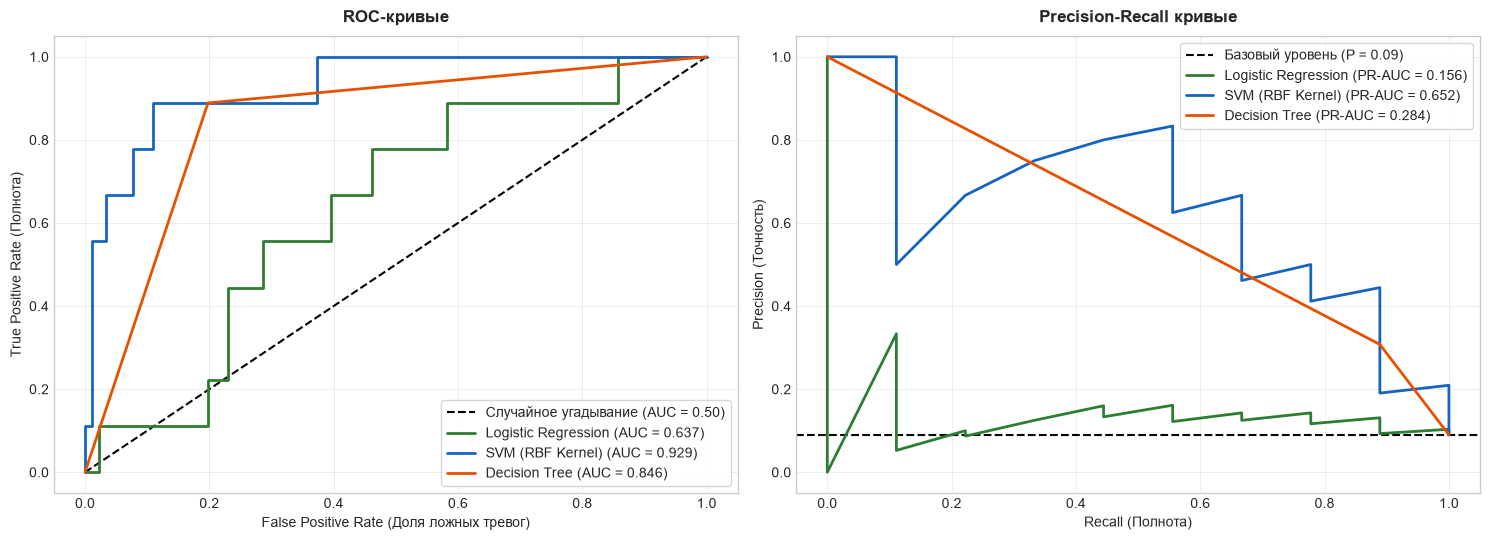

In [10]:
# 2. Графики кривых ROC-AUC и PR-AUC (Рисунок 04)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

curves_info = [
    ("Logistic Regression", log_reg.predict_proba(X_test_scaled)[:, 1], "#2E7D32"),
    ("SVM (RBF Kernel)", svm_rbf.predict_proba(X_test_scaled)[:, 1], "#1565C0"),
    ("Decision Tree", tree_clf.predict_proba(X_test_scaled)[:, 1], "#E65100")
]

# ROC-кривая
axes[0].plot([0, 1], [0, 1], "k--", lw=1.5, label="Случайное угадывание (AUC = 0.50)")
for label, probs, color in curves_info:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_score = roc_auc_score(y_test, probs)
    axes[0].plot(fpr, tpr, lw=2, label=f"{label} (AUC = {auc_score:.3f})", color=color)

axes[0].set_title("ROC-кривые", fontsize=12, fontweight="bold", pad=10)
axes[0].set_xlabel("False Positive Rate (Доля ложных тревог)")
axes[0].set_ylabel("True Positive Rate (Полнота)")
axes[0].legend(loc="lower right", frameon=True)

# PR-кривая (Precision-Recall)
baseline_p = np.mean(y_test)
axes[1].axhline(y=baseline_p, color="black", linestyle="--", lw=1.5, label=f"Базовый уровень (P = {baseline_p:.2f})")
for label, probs, color in curves_info:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    ap_score = average_precision_score(y_test, probs)
    axes[1].plot(rec, prec, lw=2, label=f"{label} (PR-AUC = {ap_score:.3f})", color=color)

axes[1].set_title("Precision-Recall кривые", fontsize=12, fontweight="bold", pad=10)
axes[1].set_xlabel("Recall (Полнота)")
axes[1].set_ylabel("Precision (Точность)")
axes[1].legend(loc="upper right", frameon=True)

plt.tight_layout()

# Явное сохранение скриншота графика на диск
img_path_04 = IMAGES_DIR / "04_roc_pr_curves_comparison.png"
fig.savefig(img_path_04, dpi=300)
print(f"[Сохранено изображение]: {img_path_04}")

plt.show()


## 7. Исследование переобучения дерева решений (max_depth)

Деревья решений склонны к **переобучению** (Overfitting):
- Если глубина дерева слишком мала ($d=1, 2$), дерево **недообучено** (слишком простое, правила примитивны).
- Если глубина не ограничена ($d \ge 8$), дерево запоминает шум обучающих данных (точность на Train достигает 100%), но на тесте точность падает.
- График наглядно демонстрирует оптимум при глубине `max_depth = 4`.

[Сохранено изображение]: images\06_cart_depth_tuning.png


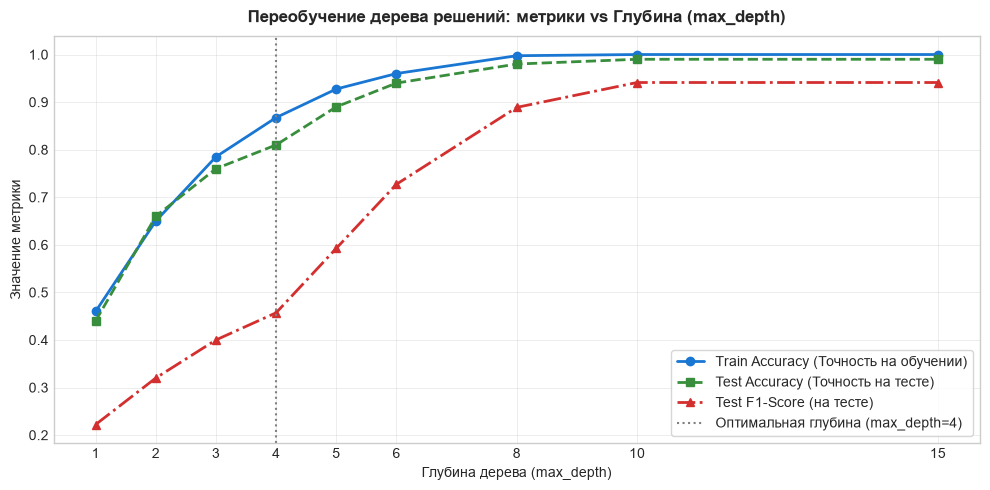

,Depth,Train_Accuracy,Test_Accuracy,Test_F1
0,1,0.4600,0.44,0.222222
1,2,0.6500,0.66,0.320000
2,3,0.7850,0.76,0.400000
3,4,0.8675,0.81,0.457143
4,5,0.9275,0.89,0.592593
5,6,0.9600,0.94,0.727273
6,8,0.9975,0.98,0.888889
7,10,1.0000,0.99,0.941176
8,15,1.0000,0.99,0.941176


In [11]:
# Исследование зависимости качества от глубины дерева (Рисунок 06)
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15]
depth_results = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE)
    clf.fit(X_train_scaled, y_train)
    
    depth_results.append({
        "Depth": d,
        "Train_Accuracy": clf.score(X_train_scaled, y_train),
        "Test_Accuracy": clf.score(X_test_scaled, y_test),
        "Test_F1": f1_score(y_test, clf.predict(X_test_scaled), zero_division=0)
    })

df_depth = pd.DataFrame(depth_results)

# Построение графика переобучения
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_depth["Depth"], df_depth["Train_Accuracy"], "o-", label="Train Accuracy (Точность на обучении)", color="#1976D2", lw=2)
ax.plot(df_depth["Depth"], df_depth["Test_Accuracy"], "s--", label="Test Accuracy (Точность на тесте)", color="#388E3C", lw=2)
ax.plot(df_depth["Depth"], df_depth["Test_F1"], "^-.", label="Test F1-Score (на тесте)", color="#D32F2F", lw=2)

ax.axvline(x=4, color="gray", linestyle=":", lw=1.5, label="Оптимальная глубина (max_depth=4)")
ax.set_title("Переобучение дерева решений: метрики vs Глубина (max_depth)", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Глубина дерева (max_depth)")
ax.set_ylabel("Значение метрики")
ax.set_xticks(depths)
ax.legend(frameon=True)

plt.tight_layout()

# Явное сохранение скриншота графика на диск
img_path_06 = IMAGES_DIR / "06_cart_depth_tuning.png"
fig.savefig(img_path_06, dpi=300)
print(f"[Сохранено изображение]: {img_path_06}")

plt.show()

df_depth


## 8. Итоговые выводы по работе

1. **Выбор модели:**
   - Линейные модели (логистическая регрессия и линейный SVM) дают невысокий $F1 \approx 0.21 - 0.24$, так как разделяющая граница в пространстве пищевых нутриентов имеет сложную нелинейную форму.
   - **Наилучшие результаты показал SVM с ядром RBF (`kernel='rbf'`):** точность $Accuracy = 93\%$, $F1 = 0.6316$ и $ROC\text{-}AUC = 0.9292$.
2. **Дисбаланс классов:**
   - Так как полезных блюд всего 9.4%, использование параметра `class_weight="balanced"` было обязательным, что позволило деревьям и SVM распознать до $89\%$ всех полезных блюд.
3. **Регуляризация дерева:**
   - Ограничение максимальной глубины дерева решений (`max_depth = 4`) предотвратило переобучение, обеспечив $F1 = 0.4571$.